# Module 6 · Clinical "what-if" experiments

These experiments use the Module 1 model to illustrate **mechanisms**, not to predict patient values (the parameters come from the squid axon).

| Scenario | Model change | Clinical counterpart |
|---|---|---|
| Na⁺ channel block | lower `gNa` | lidocaine, phenytoin, carbamazepine; TTX poisoning |
| K⁺ channel block | lower `gK` | 4-aminopyridine (dalfampridine) in multiple sclerosis |
| Hyperkalaemia | shift `EK` (Nernst) | renal failure, rhabdomyolysis; depolarisation block |
| Loss of inhibition | lower `g` in Module 4 | seizures, GABAergic dysfunction |

In [1]:
import sys, inspect
sys.path.insert(0, '..')            # make the neurosim package importable
import numpy as np
import matplotlib.pyplot as plt
import neurosim as ns
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

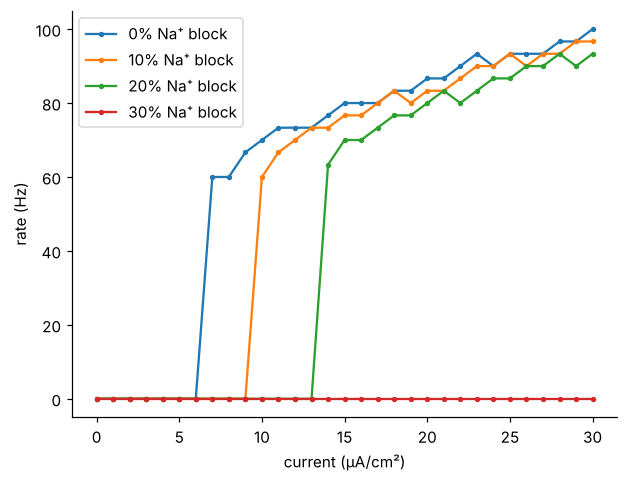

In [2]:
I = np.arange(0, 30.1, 1.0)
for block in (0.0, 0.1, 0.2, 0.3):
    plt.plot(I, ns.fi_curve(I, ns.sodium_block(block), duration=400), 'o-', ms=2.5, label=f'{block:.0%} Na⁺ block')
plt.xlabel('current (µA/cm²)'); plt.ylabel('rate (Hz)'); plt.legend(); plt.show()

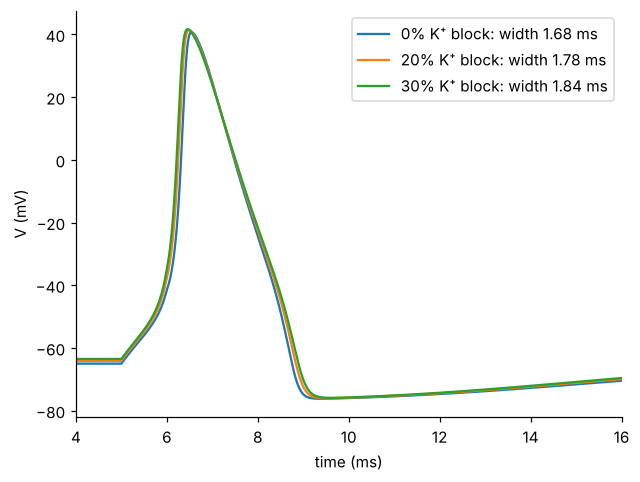

In [3]:
for block in (0.0, 0.2, 0.3):
    w, r = ns.spike_width(ns.potassium_block(block))
    plt.plot(r['t'], r['V'], label=f'{block:.0%} K⁺ block: width {w:.2f} ms')
plt.xlim(4, 16); plt.xlabel('time (ms)'); plt.ylabel('V (mV)'); plt.legend(); plt.show()

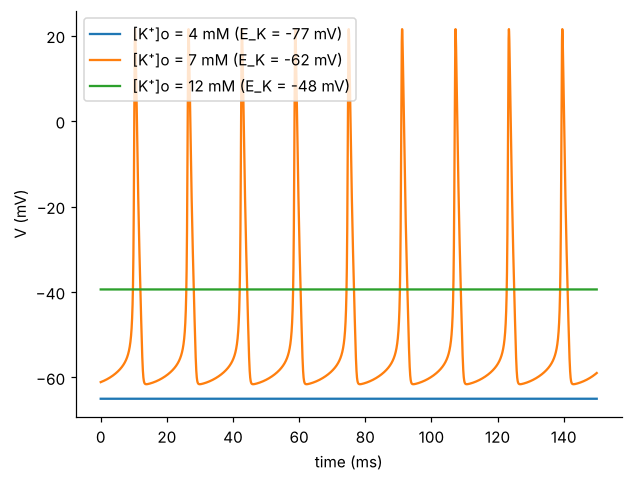

In [4]:
for K in (4, 7, 12):
    p = ns.extracellular_potassium(K)
    r = ns.simulate_hh(0.0, 150, params=p, init=ns.settle(p))
    plt.plot(r['t'], r['V'], label=f'[K⁺]o = {K} mM (E_K = {p["EK"]:.0f} mV)')
plt.xlabel('time (ms)'); plt.ylabel('V (mV)'); plt.legend(); plt.show()

## Exercises
1. **Use-dependence.** Real lidocaine blocks more during fast firing. Make `gNa` decrease by 2 % after each spike and recover slowly. Does high-frequency firing fail first?
2. **Safety margin.** What fraction of Na⁺ block abolishes repetitive firing at 20 µA/cm²?
3. **4-AP and seizures.** Increase the K⁺ block to 40-50 %. Why might a drug that improves conduction also lower the seizure threshold?
4. **Hyperkalaemia.** Find the [K⁺]o at which spontaneous firing appears and the value at which it stops. Explain the second transition with the gate `h`.
5. **Hypokalaemia.** Try [K⁺]o = 2.5 mM. What happens to excitability?